# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

(299, 13)
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object 

Missing values per column:
 age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64 

Duplicate rows: 0
anaemia [np.int64(0), np.int64(1)]
diabetes [np.int64(0

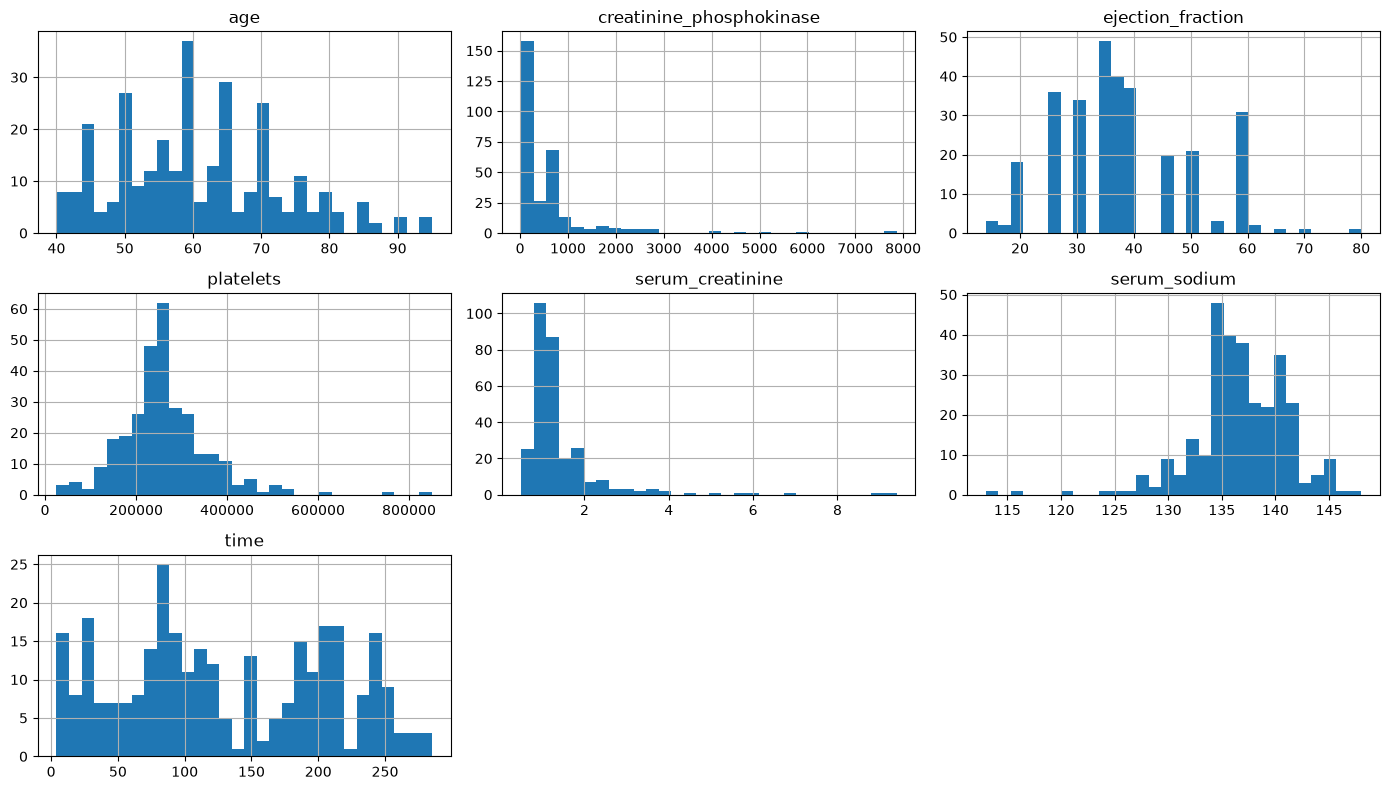

creatinine_phosphokinase | most common values: {582: 47, 129: 4, 66: 4} | column mean: 581.84
platelets | most common values: {263358.03: 25, 237000.0: 4, 228000.0: 4} | column mean: 263358.03
serum_creatinine | most common values: {1.0: 50, 1.1: 32, 0.9: 32} | column mean: 1.39
age | most common values: {60.0: 33, 50.0: 27, 65.0: 26} | column mean: 60.83


,count,mean,std,min,25%,50%,75%,max
DEATH_EVENT,,,,,,,,
0,203.0,158.339901,67.742872,12.0,95.0,172.0,213.00,285.0
1,96.0,70.885417,62.378281,4.0,25.5,44.5,102.25,241.0


In [6]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix

pd.set_option('display.width', 200)

## Q1. Data cleaning
df = pd.read_csv('./data/heart_failure/heart_failure_clinical_records_dataset.csv')
print(df.shape)
df.head()

# Data types, missing values, duplicate rows
print(df.dtypes, '\n')
print('Missing values per column:\n', df.isna().sum(), '\n')
print('Duplicate rows:', df.duplicated().sum())

df.describe().T

# Binary variables should only take the values 0 and 1
binary_vars = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking', 'DEATH_EVENT']
for var in binary_vars:
    print(var, sorted(df[var].unique()))

# Distributions of the numeric variables
numeric_vars = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets',
                'serum_creatinine', 'serum_sodium', 'time']
df[numeric_vars].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

# Suspicious repeated values: are some values placeholders for missing data?
for var in ['creatinine_phosphokinase', 'platelets', 'serum_creatinine', 'age']:
    print(var, '| most common values:', df[var].value_counts().head(3).to_dict(),
          '| column mean:', round(df[var].mean(), 2))

# `time` is the follow-up period. Patients who died have much shorter follow-up,
# because follow-up ends when they die.
df.groupby('DEATH_EVENT')['time'].describe()


**What the exploration shows**

- 299 rows, 13 columns, all numeric. There are **no missing values** and **no duplicate rows**.
- The binary variables (`anaemia`, `diabetes`, `high_blood_pressure`, `sex`, `smoking`, `DEATH_EVENT`) only take the values 0 and 1, so there are no coding errors.
- Ranges look clinically plausible (age 40–95, ejection fraction 14-80%, serum sodium 113–148 mEq/L).
- **Hidden imputation:** `creatinine_phosphokinase = 582` appears 47 times and `platelets = 263358.03` appears 25 times. Both are equal to the column mean, so those values were mean-imputed for missing data in the original source. Ages like `60.667` are also not real ages. I keep these rows (dropping them would lose a lot of data), but I add indicator columns so the models can tell imputed values apart.
- `creatinine_phosphokinase` and `serum_creatinine` are **very right-skewed** (a few extreme values, e.g. CPK up to 7861). I log-transform them so a few extreme values don't dominate the linear model.
- `platelets` is on a huge scale (hundreds of thousands), so I rescale it to thousands to make its coefficient readable.
- **`time` is dropped.** It is the follow-up period, and it is short *because* the patient died (mean 71 days for deaths vs. 158 for survivors). It is information you would not have when making a prediction about a new patient, so using it would leak the outcome into the model.

In [8]:
df_clean = df.copy()

# Flags for mean-imputed values
df_clean['cpk_imputed'] = (df_clean['creatinine_phosphokinase'] == 582).astype(int)
df_clean['platelets_imputed'] = np.isclose(df_clean['platelets'], 263358.03).astype(int)

# Log-transform the right-skewed lab values
df_clean['log_cpk'] = np.log(df_clean['creatinine_phosphokinase'])
df_clean['log_serum_creatinine'] = np.log(df_clean['serum_creatinine'])

# Rescale platelets to thousands
df_clean['platelets_k'] = df_clean['platelets'] / 1000

# Round the non-integer ages
df_clean['age'] = df_clean['age'].round()

# Drop the raw versions and `time` (outcome leakage)
df_clean = df_clean.drop(columns=['creatinine_phosphokinase', 'serum_creatinine', 'platelets', 'time'])

df_clean.describe().T

y = df_clean['DEATH_EVENT']
X = df_clean.drop(columns='DEATH_EVENT')
print(X.shape)
print('Share of patients who died:', round(y.mean(), 3))
list(X.columns)

(299, 13)
Share of patients who died: 0.321


['age',
 'anaemia',
 'diabetes',
 'ejection_fraction',
 'high_blood_pressure',
 'serum_sodium',
 'sex',
 'smoking',
 'cpk_imputed',
 'platelets_imputed',
 'log_cpk',
 'log_serum_creatinine',
 'platelets_k']

## Q2. Train-test split, tree and linear model (logistic regression)

I use an 80/20 split with seed `42`, stratified on `DEATH_EVENT` so both sets have the same share of deaths.

Train size: 239 | Test size: 60


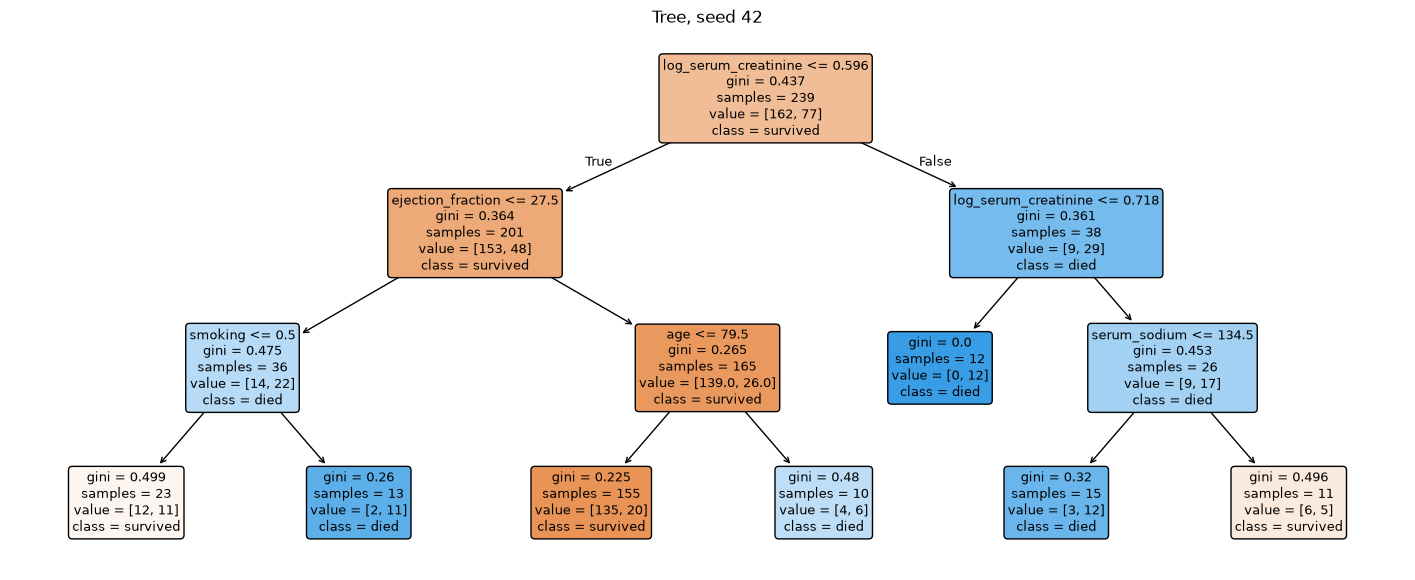

Share of deaths in the test set: 0.317 -> accuracy of always predicting "survived": 0.683
Tree


,Predicted survival (0),Predicted death (1)
Observed survival (0),37,4
Observed death (1),9,10


Logistic


,Predicted survival (0),Predicted death (1)
Observed survival (0),35,6
Observed death (1),11,8


In [10]:
BASE_SEED = 42      # seed for question 2 (saved for reproducibility)
TEST_SIZE = 0.2
MAX_DEPTH = 3       # keep the tree small enough to read

def fit_models(seed):
    """Split the data with `seed`, then fit a tree and a logistic regression on the training set."""
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=seed, stratify=y)
    tree = DecisionTreeClassifier(max_depth=MAX_DEPTH, random_state=seed).fit(X_train, y_train)
    lm = LogisticRegression(C=np.inf, max_iter=10000, tol=1e-8).fit(X_train, y_train)
    return tree, lm, X_train, X_test, y_train, y_test

def evaluate(tree, lm, X_test, y_test):
    """Test-set BCE (log loss) of the predicted probabilities, and accuracy at threshold 0.5."""
    rows = []
    for name, m in [('Tree', tree), ('Logistic', lm)]:
        p = m.predict_proba(X_test)[:, 1]
        rows.append({'model': name,
                     'accuracy': accuracy_score(y_test, m.predict(X_test)),
                     'BCE': log_loss(y_test, p)})
    return pd.DataFrame(rows).round(3)

tree_base, lm_base, X_train_base, X_test_base, y_train_base, y_test_base = fit_models(BASE_SEED)
print('Train size:', len(X_train_base), '| Test size:', len(X_test_base))

# The tree
plt.figure(figsize=(18, 7))
plot_tree(tree_base, feature_names=X.columns, class_names=['survived', 'died'],
          filled=True, rounded=True, fontsize=9)
plt.title(f'Tree, seed {BASE_SEED}')
plt.show()

# Logistic regression coefficients (log-odds scale)
pd.Series(lm_base.coef_[0], index=X.columns).round(4).to_frame(f'coef (seed {BASE_SEED})')

# Performance on the test set
print('Share of deaths in the test set:', round(y_test_base.mean(), 3),
      '-> accuracy of always predicting "survived":', round(1 - y_test_base.mean(), 3))
evaluate(tree_base, lm_base, X_test_base, y_test_base)

# Confusion matrices on the test set (rows = observed, columns = predicted)
for name, m in [('Tree', tree_base), ('Logistic', lm_base)]:
    cm = pd.DataFrame(confusion_matrix(y_test_base, m.predict(X_test_base)),
                      index=['Observed survival (0)', 'Observed death (1)'],
                      columns=['Predicted survival (0)', 'Predicted death (1)'])
    print(name); display(cm)


# Set aside the base predictions on the question-2 test set
pred_tree_base = tree_base.predict_proba(X_test_base)[:, 1]
pred_lm_base = lm_base.predict_proba(X_test_base)[:, 1]

**Q2 results (seed 42).** The tree's first split is on `log_serum_creatinine` (about serum creatinine 1.8 mg/dL), then on `ejection_fraction`, `age` and `serum_sodium`. The logistic regression also puts the most weight on serum creatinine. Its coefficients are on the log-odds scale: +2.00 for `log_serum_creatinine` (doubling creatinine multiplies the odds of death by about e^(2.00 × ln 2) ≈ 4), -0.064 for `ejection_fraction` (each extra percentage point multiplies the odds by e^-0.064 ≈ 0.94) and +0.040 for `age` (each year multiplies the odds by about 1.04).

On the test set the tree has 78.3% accuracy and BCE 0.516, and the logistic regression has 71.7% accuracy and BCE 0.570. Always predicting "survived" would get 68.3%, so both beat that baseline, the tree by more on this split. The confusion matrices show both models miss many deaths at threshold 0.5: the tree misses 9 of the 19 observed deaths and the logistic regression misses 11. The predicted probabilities of death (`pred_tree_base`, `pred_lm_base`) are saved for Q4.

## Q3. Repeating the analysis across seeds

I repeat step 2 with four more seeds. Each model is trained on its *own* training split. For Q4, every model also predicts on the **question-2 test set** (`X_test_base`), so all predictions are for the same 60 patients.

===== Tree, seed 42 =====
|--- log_serum_creatinine <= 0.60
|   |--- ejection_fraction <= 27.50
|   |   |--- smoking <= 0.50
|   |   |   |--- class: 0
|   |   |--- smoking >  0.50
|   |   |   |--- class: 1
|   |--- ejection_fraction >  27.50
|   |   |--- age <= 79.50
|   |   |   |--- class: 0
|   |   |--- age >  79.50
|   |   |   |--- class: 1
|--- log_serum_creatinine >  0.60
|   |--- log_serum_creatinine <= 0.72
|   |   |--- class: 1
|   |--- log_serum_creatinine >  0.72
|   |   |--- serum_sodium <= 134.50
|   |   |   |--- class: 1
|   |   |--- serum_sodium >  134.50
|   |   |   |--- class: 0

===== Tree, seed 1 =====
|--- log_serum_creatinine <= 0.60
|   |--- ejection_fraction <= 27.50
|   |   |--- serum_sodium <= 143.00
|   |   |   |--- class: 1
|   |   |--- serum_sodium >  143.00
|   |   |   |--- class: 0
|   |--- ejection_fraction >  27.50
|   |   |--- age <= 79.50
|   |   |   |--- class: 0
|   |   |--- age >  79.50
|   |   |   |--- class: 1
|--- log_serum_creatinine >  0.60
|   

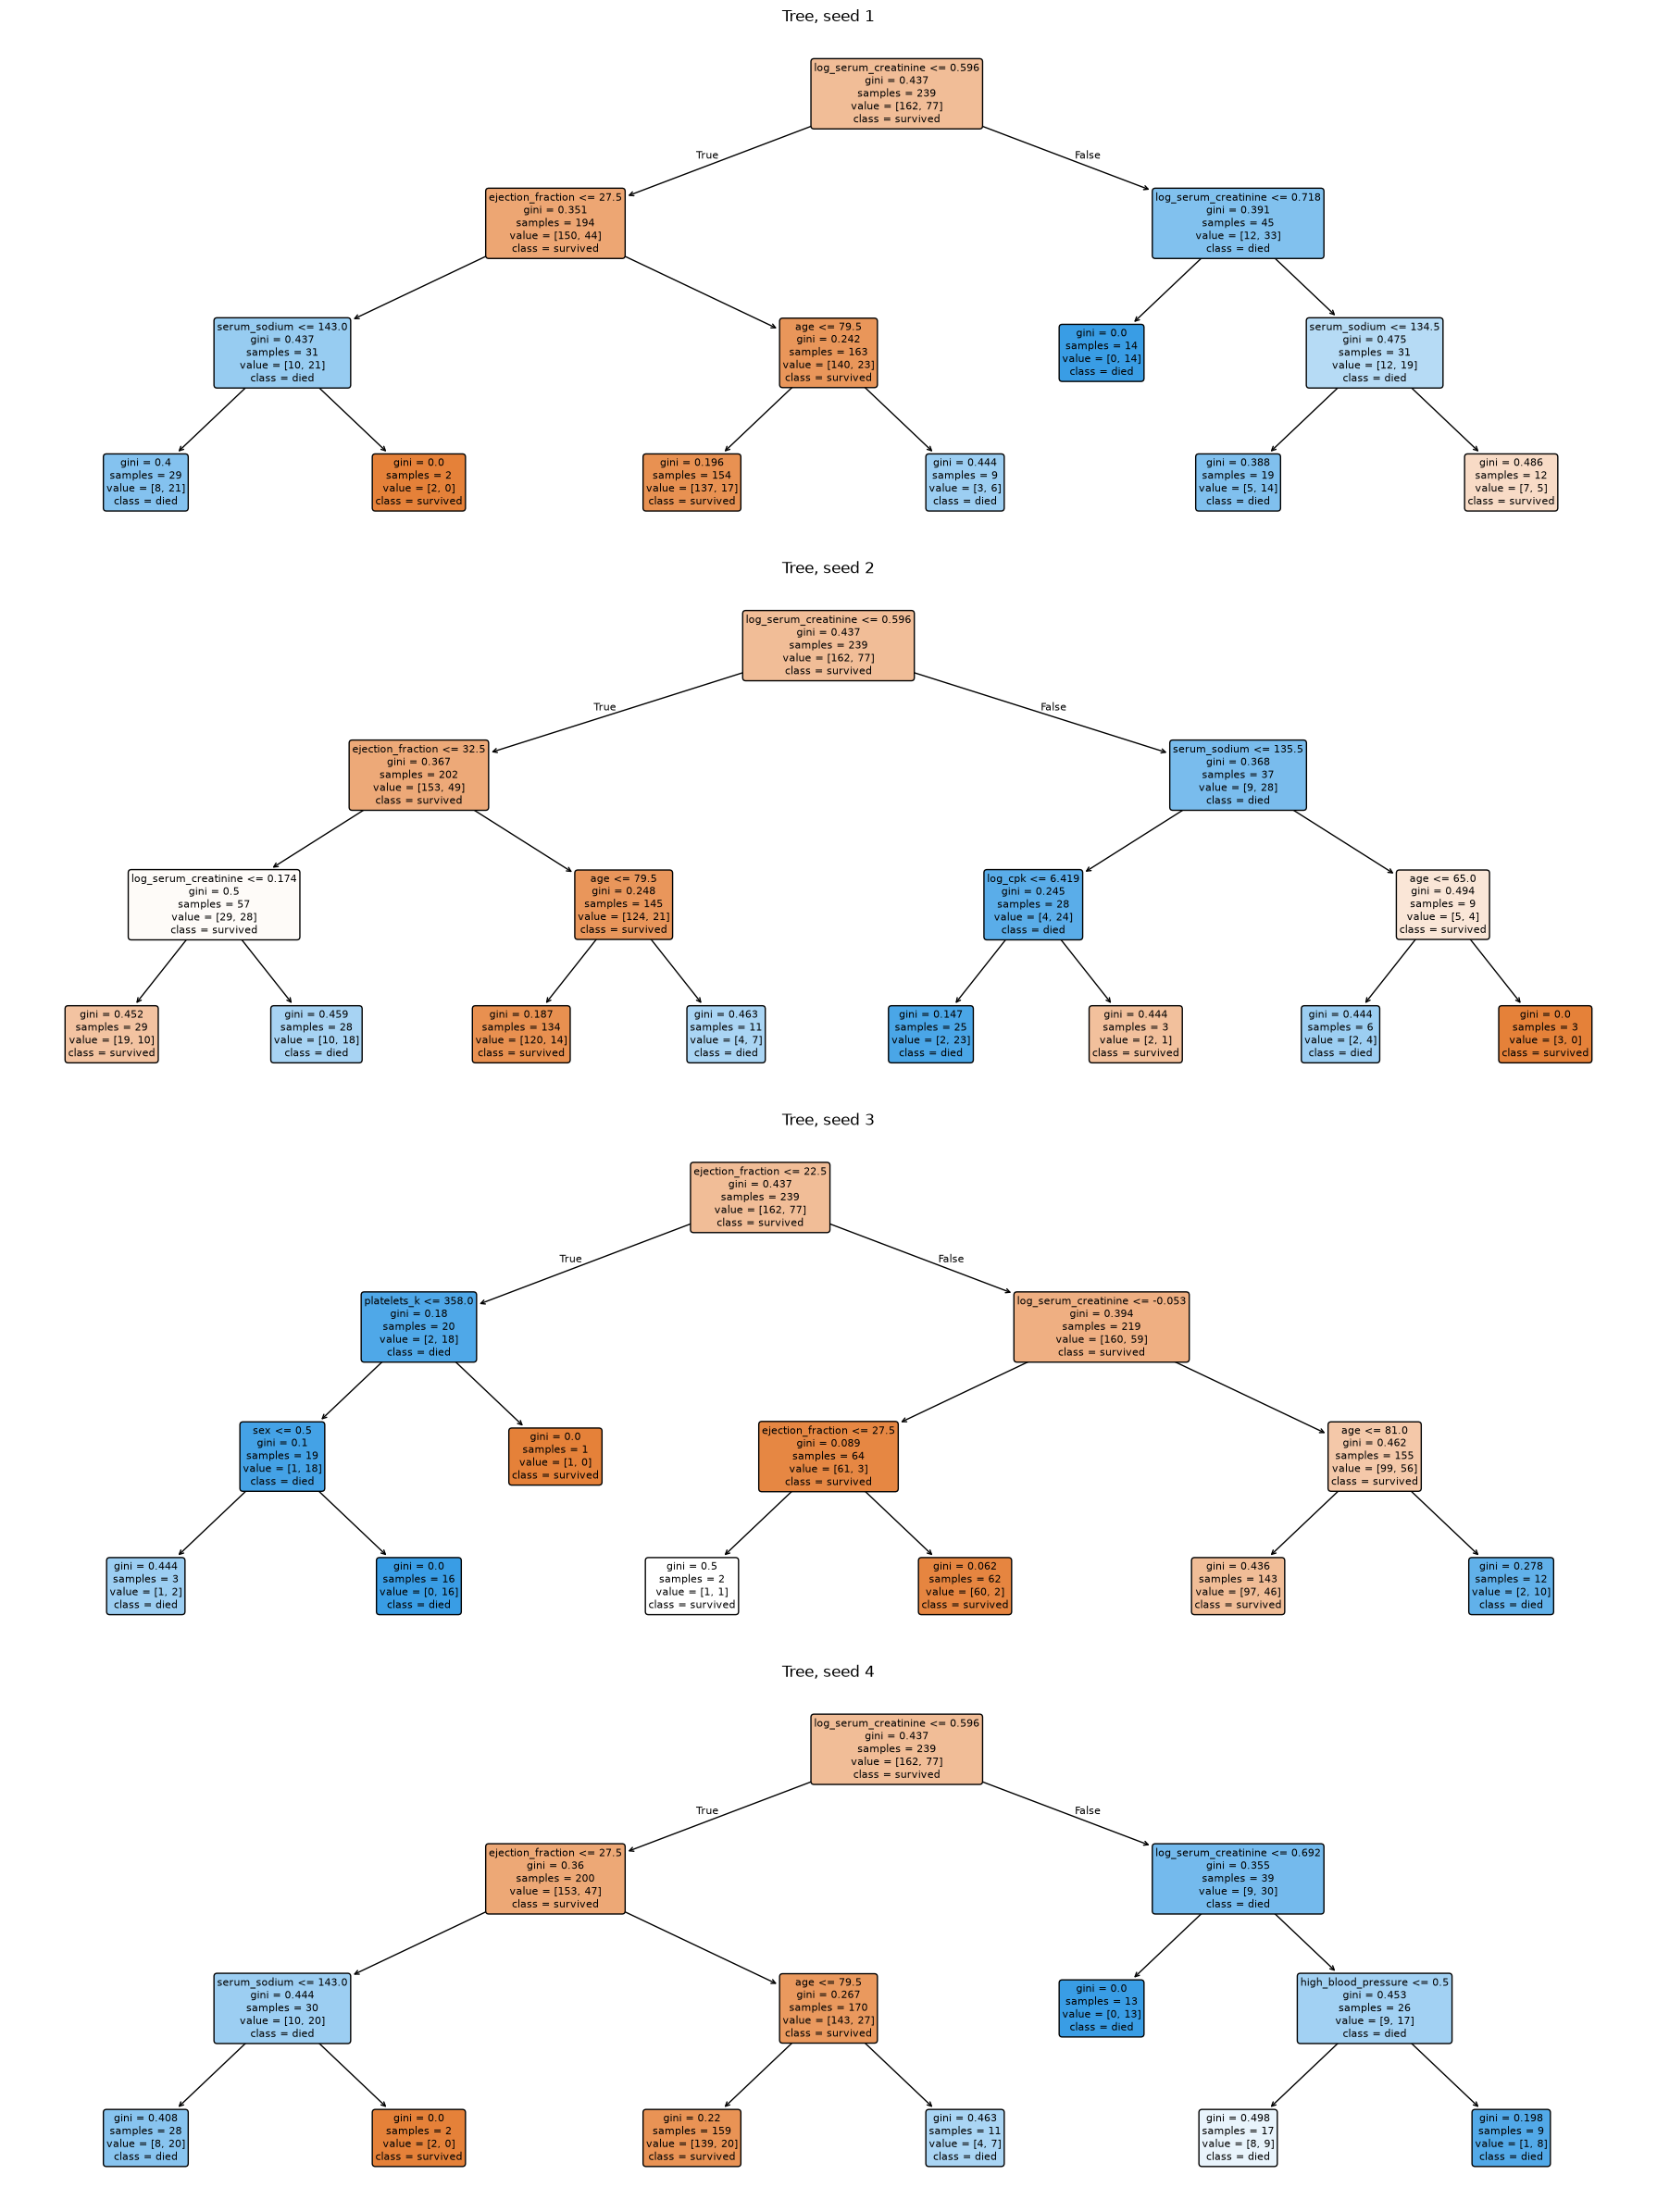

,seed 42,seed 1,seed 2,seed 3,seed 4,mean,std,std / |mean|,same sign?
age,0.0396,0.0482,0.0437,0.0487,0.0400,0.0440,0.0043,0.0987,True
anaemia,0.6669,0.5549,0.3167,0.5589,0.4513,0.5098,0.1321,0.2592,True
diabetes,0.5227,-0.2574,0.1429,0.0728,0.3149,0.1592,0.2905,1.8252,False
ejection_fraction,-0.0643,-0.0812,-0.0652,-0.0563,-0.0644,-0.0663,0.0091,0.1373,True
high_blood_pressure,0.7271,0.1724,0.3689,0.1797,0.4479,0.3792,0.2283,0.6020,True
serum_sodium,-0.0170,-0.0261,-0.0638,-0.0664,-0.0271,-0.0401,0.0232,0.5784,True
sex,-0.2557,-0.8010,-0.4352,-0.3508,-0.5524,-0.4790,0.2105,0.4395,True
smoking,0.4901,0.0626,0.1609,0.2018,0.1493,0.2129,0.1630,0.7657,True
cpk_imputed,-0.0279,0.0625,0.2893,-0.1312,0.3325,0.1051,0.2006,1.9093,False
platelets_imputed,0.0402,0.6738,0.2897,0.5960,0.2578,0.3715,0.2604,0.7008,True


In [11]:
ALT_SEEDS = [1, 2, 3, 4]   # seeds for question 3 (saved for reproducibility)

alt_trees, alt_lms = {}, {}
pred_tree_alt, pred_lm_alt = {}, {}
perf = [evaluate(tree_base, lm_base, X_test_base, y_test_base).assign(seed=BASE_SEED)]

for s in ALT_SEEDS:
    tree_s, lm_s, X_tr, X_te, y_tr, y_te = fit_models(s)
    alt_trees[s], alt_lms[s] = tree_s, lm_s
    perf.append(evaluate(tree_s, lm_s, X_te, y_te).assign(seed=s))   # on its own test set
    # Predictions on the question-2 test set, set aside for Q4
    pred_tree_alt[s] = tree_s.predict_proba(X_test_base)[:, 1]
    pred_lm_alt[s] = lm_s.predict_proba(X_test_base)[:, 1]

perf_df = pd.concat(perf).pivot(index='seed', columns='model', values=['accuracy', 'BCE'])
perf_df

# Compare the trees: the text version of every tree
for s, t in [(BASE_SEED, tree_base)] + list(alt_trees.items()):
    print(f'===== Tree, seed {s} =====')
    print(export_text(t, feature_names=list(X.columns), decimals=2))

# Plot every tree
fig, axes = plt.subplots(len(ALT_SEEDS), 1, figsize=(18, 6 * len(ALT_SEEDS)))
for ax, (s, t) in zip(axes, alt_trees.items()):
    plot_tree(t, feature_names=X.columns, class_names=['survived', 'died'],
              filled=True, rounded=True, fontsize=8, ax=ax)
    ax.set_title(f'Tree, seed {s}')
plt.tight_layout()
plt.show()

# Which variables does each tree split on, and at what threshold?
def splits(t):
    tr = t.tree_
    return [f'{X.columns[f]} <= {th:.2f}' for f, th in zip(tr.feature, tr.threshold) if f >= 0]

pd.DataFrame({s: pd.Series(splits(t)) for s, t in [(BASE_SEED, tree_base)] + list(alt_trees.items())}).fillna('')

# Compare the logistic regression coefficients
coefs = pd.DataFrame({f'seed {s}': m.coef_[0] for s, m in [(BASE_SEED, lm_base)] + list(alt_lms.items())},
                     index=X.columns)
coefs['mean'] = coefs.mean(axis=1)
coefs['std'] = coefs.iloc[:, :-1].std(axis=1)
coefs['std / |mean|'] = coefs['std'] / coefs['mean'].abs()
coefs['same sign?'] = (np.sign(coefs.iloc[:, :len(ALT_SEEDS) + 1]).nunique(axis=1) == 1)
coefs.round(4)

**How different are the trees?** Noticeably different. Seeds 42, 1 and 4 produce trees with almost the same top structure (root split on serum creatinine, then ejection fraction <= 27.5, then age <= 79.5), but the lower splits change: seed 42 splits on `smoking`, seeds 1 and 4 on `serum_sodium`, and seed 4 adds a `high_blood_pressure` split. Seed 2 keeps the same root but has a different right-hand branch (serum sodium, `log_cpk`, age). **Seed 3 is a completely different tree**: its root is `ejection_fraction <= 22.5`, and it splits on platelets and sex, which no other tree uses. A small change in which 239 patients land in the training set can change the root split, and because every split below depends on the one above, the whole tree changes.

**How different are the logistic regression coefficients?** Much less. The strongest predictors are stable: `log_serum_creatinine` stays between 1.42 and 2.00, `ejection_fraction` between -0.056 and -0.081, and `age` between 0.040 and 0.049, all with the same sign in every split (std / |mean| around 0.1–0.15). The weaker predictors move a lot more: `smoking` ranges from 0.06 to 0.49 and `high_blood_pressure` from 0.17 to 0.73, and `diabetes`, `cpk_imputed` and `platelets_k` even change sign across seeds. Still, the overall picture (high creatinine, low ejection fraction and older age raise the odds of death) is the same in every model.

Test-set performance also varies by seed: tree accuracy 0.72-0.78, logistic accuracy 0.67-0.77. The tree's BCE jumps around much more (0.52 to 1.82) than the logistic regression's (0.48 to 0.66). Some tree leaves are pure, so they predict a probability of exactly 0 or 1, and a confidently wrong prediction gets a huge log loss.

## Q4. Comparing predictions across models

**Why do the linear coefficients vary by different amounts?**

The coefficients vary by different amounts because each one is estimated with a different amount of uncertainty. Variables with a **strong, consistent relationship** to death (serum creatinine, ejection fraction, age) are pinned down well by any 80% sample, so their coefficients barely move relative to their size. Variables with **little real relationship** to the outcome (diabetes, smoking, platelets, `cpk_imputed`) have true effects near zero, so their estimates are mostly noise: swapping a few patients in or out shifts them a lot relative to their size and can even flip their sign. **Correlated predictors** share the same information (e.g. `cpk_imputed` with `log_cpk`, `platelets_imputed` with `platelets_k`), so the model can move weight between them from one split to the next, which inflates their variability. Binary variables where few patients are in one group (e.g. the imputed flags) are estimated from only a handful of patients, which adds noise too. Finally, there are only about 77 deaths in each training set and the model is unpenalized (`C=np.inf`), so nothing shrinks the noisy coefficients toward zero. A ridge penalty would make them more stable.

### 4a. Scatterplots of question-2 predictions vs. alternative-model predictions (question-2 test set)

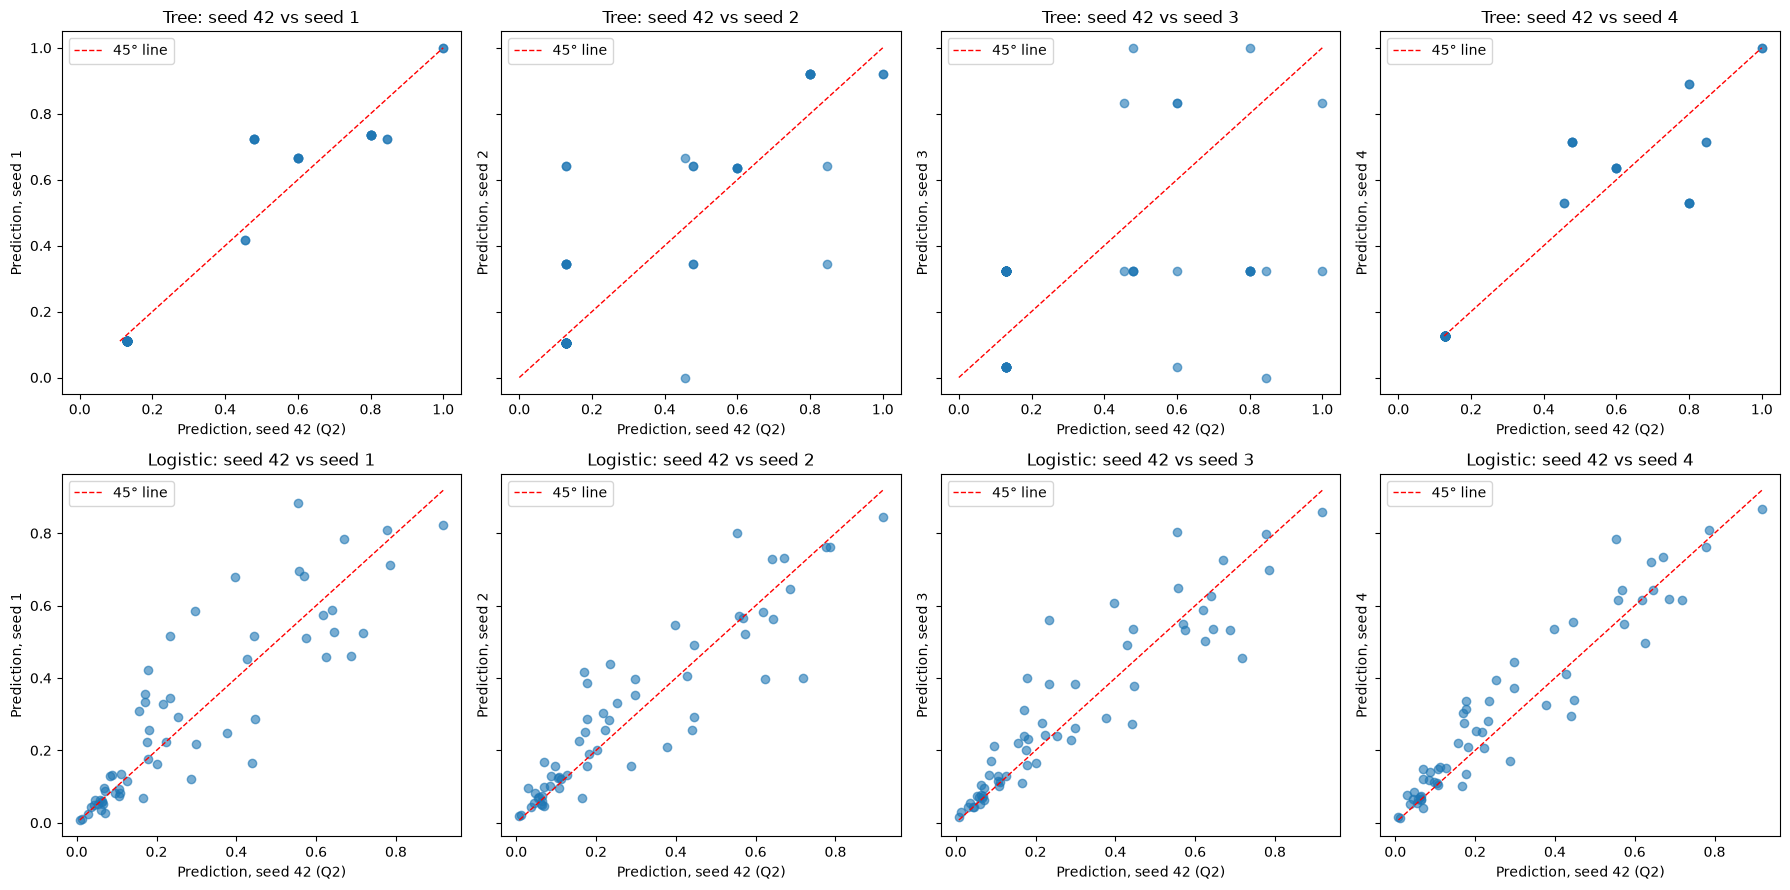

In [12]:
fig, axes = plt.subplots(2, len(ALT_SEEDS), figsize=(4.5 * len(ALT_SEEDS), 9), sharex='row', sharey='row')
rows = [('Tree', pred_tree_base, pred_tree_alt), ('Logistic', pred_lm_base, pred_lm_alt)]
for r, (name, base, alt) in enumerate(rows):
    for c, s in enumerate(ALT_SEEDS):
        ax = axes[r, c]
        ax.scatter(base, alt[s], alpha=0.6)
        lo = min(base.min(), alt[s].min()); hi = max(base.max(), alt[s].max())
        ax.plot([lo, hi], [lo, hi], 'r--', lw=1, label='45° line')
        ax.set_title(f'{name}: seed {BASE_SEED} vs seed {s}')
        ax.set_xlabel(f'Prediction, seed {BASE_SEED} (Q2)')
        ax.set_ylabel(f'Prediction, seed {s}')
        ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

**Logistic regression:** Yes, very similar. For all four alternative seeds the points sit in a fairly tight band along the 45° line, so a patient the seed-42 model rates as high-risk is also rated high-risk by the other models. The band is a bit wider for seed 1, which also has the lowest correlation in 4b.

**Trees:** It depends on the seed. A tree only has a few leaves, so it can only output a few distinct probabilities, and many patients are stacked on top of each other in each dot. For seeds 1 and 4 the dots sit close to the 45° line, so the predictions are reasonably similar even though the trees look somewhat different. Seed 2 is looser, with some patients moved to quite different leaves. Seed 3 (the tree with a different root split) shows almost no relationship: patients the seed-42 tree gives a 0.8-1.0 probability can get 0.3 from the seed-3 tree, and vice versa. So the trees' predictions are mostly similar, but much less consistently so than the logistic regressions'.

### 4b. Correlation between the question-2 model and the alternative models

In [13]:
corr = pd.DataFrame({
    'Tree': {s: np.corrcoef(pred_tree_base, pred_tree_alt[s])[0, 1] for s in ALT_SEEDS},
    'Logistic': {s: np.corrcoef(pred_lm_base, pred_lm_alt[s])[0, 1] for s in ALT_SEEDS},
})
corr.index.name = 'alternative seed'
corr.loc['mean'] = corr.mean()
corr.round(3)

,Tree,Logistic
alternative seed,,
1,0.968,0.877
2,0.857,0.912
3,0.390,0.920
4,0.938,0.954
mean,0.788,0.916


**Logistic regression:** Highly correlated. The correlations with the seed-42 model are 0.88, 0.91, 0.92 and 0.95 (mean 0.92).

**Trees:** Mostly highly correlated, but not always. Seeds 1, 2 and 4 have correlations of 0.97, 0.86 and 0.94, which are high. Seed 3 only has 0.39, a weak relationship, because that tree has a different root split. The mean correlation for trees (0.79) is clearly lower than for logistic regression (0.92), and it varies far more across seeds (0.39-0.97 vs. 0.88-0.95). The best tree pair (0.97) is actually more similar than any logistic pair, because those two trees have almost the same splits and so put patients in the same leaves.

### 4c. Regression of alternative-model predictions on question-2 predictions

For each alternative seed: `prediction_alt = intercept + slope * prediction_Q2`

In [14]:
reg_rows = []
for name, base, alt in [('Tree', pred_tree_base, pred_tree_alt), ('Logistic', pred_lm_base, pred_lm_alt)]:
    for s in ALT_SEEDS:
        reg = LinearRegression().fit(base.reshape(-1, 1), alt[s])
        reg_rows.append({'model': name, 'alt seed': s,
                         'intercept': reg.intercept_, 'slope': reg.coef_[0],
                         'R^2': reg.score(base.reshape(-1, 1), alt[s])})
reg_df = pd.DataFrame(reg_rows).set_index(['model', 'alt seed'])
reg_df.round(3)

reg_df.groupby('model').mean().round(3)

,intercept,slope,R^2
model,,,
Logistic,0.045,0.900,0.839
Tree,0.068,0.794,0.676


If two models made identical predictions, the regression would give intercept = 0, slope = 1 and R² = 1.

**Logistic regression:** Close on all three. Intercepts are 0.04–0.05 (near zero on a 0-1 probability scale), slopes are 0.87-0.95 (close to 1) and R² is 0.77-0.91 (mean 0.84). The alternative models make nearly the same predictions, just slightly less spread out than the seed-42 model, which had some of the largest coefficients (e.g. the largest serum creatinine coefficient, 2.00).

**Trees:** Seeds 1 and 4 are close: intercepts -0.01 and 0.02, slopes 1.01 and 0.93, R² 0.94 and 0.88. Seed 2 is moderate (intercept 0.04, slope 0.93, R² 0.74). Seed 3 is far off: intercept 0.22, slope 0.31 and R² 0.15, so the seed-42 tree explains only 15% of the variation in the seed-3 tree's predictions. On average the trees (intercept 0.07, slope 0.79, R² 0.68) are clearly further from (0, 1, 1) than the logistic regressions (0.05, 0.90, 0.84).

## Q5. Stability of linear models and trees across splits
**Linear models (logistic regression): yes.** The coefficients that matter (serum creatinine, ejection fraction, age) are stable in size and sign across every split. The coefficients that move a lot belong to weak predictors whose true effect is close to zero. The predictions are very similar too: correlations of 0.88-0.95, and regressions with intercepts near 0, slopes near 1 and R² around 0.84. Logistic regression is a low-variance model: a small change in the training data causes a small change in the fitted model.

**Trees: not really.** Their structure changes noticeably across splits. Lower splits switch variables in almost every tree, and in one split (seed 3) even the root changes, which produces a completely different tree. Their predictions are often still similar (seeds 1, 2 and 4 have correlations of 0.86-0.97), because different trees tend to find the same high-risk patients (high creatinine, low ejection fraction, old age) through different splits. But this is not guaranteed: when the root split changes, the predictions can change a lot (seed 3: correlation 0.39, R² 0.15). Trees are high-variance models.

*Caveat:* the alternative training sets overlap heavily with the seed-42 training set and include some of the seed-42 test patients, which makes the predictions somewhat more similar than they would be on completely new patients. The dataset is also small (299 patients, about 96 deaths), which makes instability more visible.

## Q6. True or false

*"Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."*
**True, with a caveat for trees.**

The logistic regressions support the statement clearly. Their weaker coefficients change a lot (some even flip sign), but every alternative model's predictions correlate 0.88–0.95 with the original, with slopes near 1 and R² around 0.84.

For trees, the statement holds *often* but not always. Seeds 1, 2 and 4 produce trees with different lower splits, yet their predictions correlate 0.86-0.97 with the seed-42 tree, because they reach similar risk groups through different paths (serum creatinine, ejection fraction and age carry most of the signal, so any reasonable tree finds them). Seed 3 is the exception: a different root split produced a substantially different tree *and* substantially different predictions (correlation 0.39).

So for this dataset, in 7 of the 8 comparisons the predictions were highly correlated despite visible differences in the models, which makes the statement true: looking only at a tree's structure or a model's coefficients overstates how unstable the model is. But trees can occasionally change their predictions too, which is why the bootstrap-and-average approach from the ensembles lecture (bagging and random forests) averages many trees together.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]